# Binary Classification Using Single-Layer Perceptron

## 1. Introduction

In this project, we implement a Single-Layer Perceptron
from scratch using Python and NumPy.

The model uses the Breast Cancer Wisconsin (Diagnostic)
dataset to classify tumors into two categories:
Benign and Malignant.

## 2. Import Libraries and Load Dataset

We import the required libraries and load the breast
cancer dataset into a Pandas DataFrame.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('breast-cancer.csv')

display(df.head())

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (569, 32)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    flo

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [4]:
print("Class Distribution:")
print(df['diagnosis'].value_counts())

print("\nUnique Target Classes:")
print(df['diagnosis'].unique())

Class Distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64

Unique Target Classes:
<StringArray>
['M', 'B']
Length: 2, dtype: str


## 3. Exploratory Data Analysis (EDA)

EDA helps us understand the dataset and examine
the distribution of both target classes.

In [5]:
print("Total Missing Values:", df.isnull().sum().sum())

print("Total Duplicate Rows:", df.duplicated().sum())

Total Missing Values: 0
Total Duplicate Rows: 0


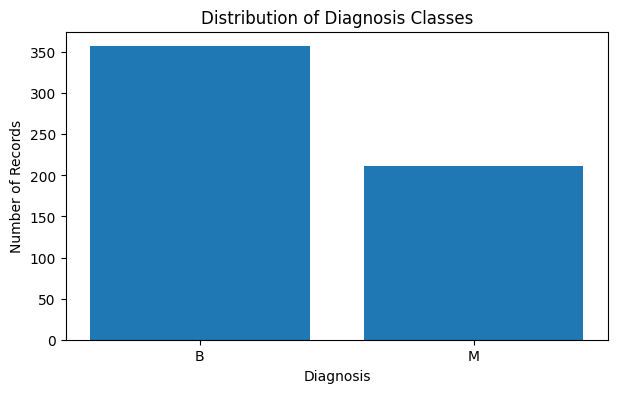

In [6]:
class_counts = df['diagnosis'].value_counts()

plt.figure(figsize=(7, 4))

plt.bar(class_counts.index, class_counts.values)

plt.title('Distribution of Diagnosis Classes')
plt.xlabel('Diagnosis')
plt.ylabel('Number of Records')

plt.show()

## 4. Data Preprocessing

Data preprocessing prepares the dataset for model training.

Steps:
- Remove the unnecessary ID column.
- Encode target classes into numerical values.
- Separate input features and target variable.

In [7]:
df = df.drop(columns=['id'])

df = df.drop_duplicates()

print("Dataset Shape After Preprocessing:", df.shape)

Dataset Shape After Preprocessing: (569, 31)


In [8]:
df['diagnosis'] = df['diagnosis'].map({
    'B': 0,
    'M': 1
})

print(df['diagnosis'].value_counts())

diagnosis
0    357
1    212
Name: count, dtype: int64


In [9]:
X = df.drop('diagnosis', axis=1).values

y = df['diagnosis'].values

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Input Features Shape: (569, 30)
Target Variable Shape: (569,)


## 5. Train-Test Split

We divide the dataset into:
- 80% training data.
- 20% testing data.

We use stratified splitting to maintain the proportion
of both classes in the training and testing datasets.

In [10]:
np.random.seed(42)

train_indices = []
test_indices = []

for class_label in [0, 1]:

    indices = np.where(y == class_label)[0]

    np.random.shuffle(indices)

    split_point = int(len(indices) * 0.8)

    train_indices.extend(indices[:split_point])
    test_indices.extend(indices[split_point:])

train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

np.random.shuffle(train_indices)
np.random.shuffle(test_indices)

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Class Distribution:")
print(np.unique(y_train, return_counts=True))

print("\nTesting Class Distribution:")
print(np.unique(y_test, return_counts=True))

Training Data: (454, 30)
Testing Data: (115, 30)

Training Class Distribution:
(array([0, 1]), array([285, 169]))

Testing Class Distribution:
(array([0, 1]), array([72, 43]))


## 6. Feature Scaling

We use Standardization to bring all numerical features
to a similar scale.

The mean and standard deviation are calculated using
training data only to prevent data leakage.

In [11]:
mean = np.mean(X_train, axis=0)

std = np.std(X_train, axis=0)

std[std == 0] = 1

X_train = (X_train - mean) / std

X_test = (X_test - mean) / std

print("Feature Scaling Completed!")

Feature Scaling Completed!


## 7. Single-Layer Perceptron Implementation

A Single-Layer Perceptron is a basic neural network
used for binary classification.

It uses:
- Weights
- Bias
- Weighted Sum
- Step Activation Function
- Perceptron Learning Rule

The model updates its weights and bias when
a prediction is incorrect.

In [12]:
weights = np.zeros(X_train.shape[1])

bias = 0.0

learning_rate = 0.01

epochs = 100

print("Number of Weights:", len(weights))
print("Initial Bias:", bias)

Number of Weights: 30
Initial Bias: 0.0


In [13]:
def activation_function(z):

    if z >= 0:
        return 1

    else:
        return 0

In [14]:
errors = []

for epoch in range(epochs):

    total_errors = 0

    for i in range(len(X_train)):

        # Calculate weighted sum
        z = np.dot(X_train[i], weights) + bias

        # Apply activation function
        prediction = activation_function(z)

        # Calculate prediction error
        error = y_train[i] - prediction

        # Update weights and bias
        if error != 0:

            weights = weights + learning_rate * error * X_train[i]

            bias = bias + learning_rate * error

            total_errors += 1

    errors.append(total_errors)

    if total_errors == 0:
        break

print("Training Completed Successfully!")

print("Total Epochs:", epoch + 1)

print("Final Bias:", bias)

print("Final Weights:")
print(weights)

Training Completed Successfully!
Total Epochs: 100
Final Bias: 0.08
Final Weights:
[-0.03441552  0.03783657 -0.00796948  0.0473454   0.08560085 -0.23652917
  0.0970029   0.21208647 -0.12589417  0.02207043  0.19773225 -0.1073182
  0.10014832  0.25919636  0.03777617 -0.05639533 -0.25447121  0.19548628
 -0.09785405 -0.03650438  0.05854041  0.18290086  0.00836646  0.12694514
 -0.00185124 -0.1668191   0.24820641  0.13831496  0.22069046  0.07497336]


## 8. Model Prediction

After training, we use the learned weights and bias
to predict the classes of unseen testing data.

In [15]:
def predict(X):

    predictions = []

    for i in range(len(X)):

        z = np.dot(X[i], weights) + bias

        prediction = activation_function(z)

        predictions.append(prediction)

    return np.array(predictions)

In [16]:
y_pred = predict(X_test)

print("Actual Values:")
print(y_test[:10])

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[0 1 0 1 0 0 1 0 0 0]

Predicted Values:
[0 1 0 1 1 0 1 0 0 0]


## 9. Model Evaluation

We evaluate our Single-Layer Perceptron using:

- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix

These metrics help us measure the classification
performance of our model.

In [17]:
TP = np.sum((y_test == 1) & (y_pred == 1))

TN = np.sum((y_test == 0) & (y_pred == 0))

FP = np.sum((y_test == 0) & (y_pred == 1))

FN = np.sum((y_test == 1) & (y_pred == 0))

print("True Positive:", TP)
print("True Negative:", TN)
print("False Positive:", FP)
print("False Negative:", FN)

True Positive: 41
True Negative: 69
False Positive: 3
False Negative: 2


In [19]:
accuracy = (TP + TN) / len(y_test)

precision = TP / (TP + FP) if (TP + FP) > 0 else 0

recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

print("Model Performance")

print("Accuracy:", round(accuracy * 100, 2), "%")

print("Precision:", round(precision, 4))

print("Recall:", round(recall, 4))

print("F1-Score:", round(f1_score, 4))

Model Performance
Accuracy: 95.65 %
Precision: 0.9318
Recall: 0.9535
F1-Score: 0.9425


In [20]:
results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Value': [
        round(accuracy, 4),
        round(precision, 4),
        round(recall, 4),
        round(f1_score, 4)
    ]
})

display(results)

,Metric,Value
0,Accuracy,0.9565
1,Precision,0.9318
2,Recall,0.9535
3,F1-Score,0.9425


## 10. Training Performance Visualization

This graph shows the number of incorrect predictions
during each training epoch.

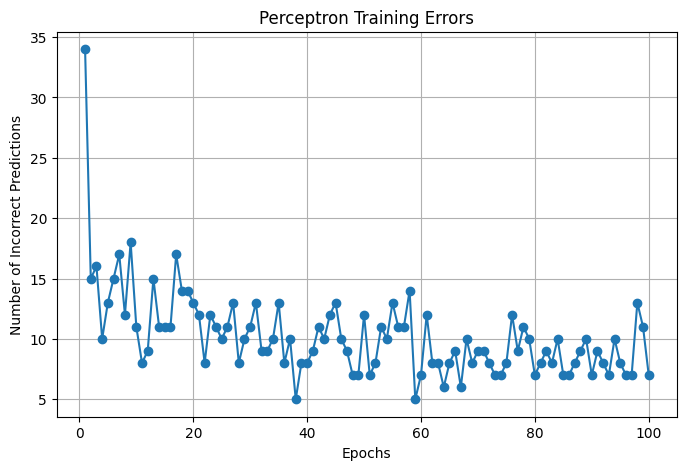

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, len(errors) + 1), errors, marker='o')

plt.title('Perceptron Training Errors')
plt.xlabel('Epochs')
plt.ylabel('Number of Incorrect Predictions')

plt.grid()
plt.show()

## 11. Confusion Matrix Visualization

The confusion matrix shows the correct and incorrect
predictions made by our model for both classes.

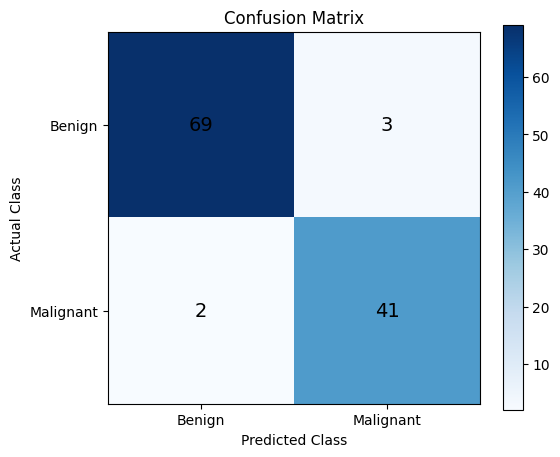

In [23]:
cm = np.array([
    [TN, FP],
    [FN, TP]
])

plt.figure(figsize=(6, 5))

plt.imshow(cm, cmap='Blues')

plt.title('Confusion Matrix')

plt.xlabel('Predicted Class')

plt.ylabel('Actual Class')

plt.xticks([0, 1], ['Benign', 'Malignant'])

plt.yticks([0, 1], ['Benign', 'Malignant'])

for i in range(2):

    for j in range(2):

        plt.text(
            j, i, cm[i, j],
            ha='center',
            va='center',
            fontsize=14
        )

plt.colorbar()

plt.show()

## 12. Conclusion

In this project, we successfully implemented a
Single-Layer Perceptron from scratch using Python and NumPy.

We performed data preprocessing, feature scaling,
and an 80:20 train-test split.

We trained the model using the Perceptron Learning Rule
and evaluated its performance using Accuracy, Precision,
Recall, F1-Score, and a Confusion Matrix.

The final results demonstrate the classification
performance of our Single-Layer Perceptron.